# 01 — Data Understanding, Audit Kualitas, & Cleaning
### Prediksi Harga Rumah di Wilayah Yogyakarta melalui Pemodelan Regresi Berbasis Data Listing Properti Daring

**Kelompok 9 — PERTALITE LANGKA** · Data Science, Informatika UPN "Veteran" Yogyakarta · 2026/2027

| Nama | NIM |
|---|---|
| Muhammad Rifty Alfattah | 123240093 |
| Muhamad Atallah Alfa Dzaky | 123240105 |
| Nicolaus Narindra Lianto | 123240100 |
| Abyaz Affanzaky Shanahan | 123240130 |

## Peta Kriteria Penilaian → 4 Notebook Modular

| No | Aspek | Item Penilaian | Notebook |
|---|---|---|---|
| 1 | Data Understanding | Sumber data, lisensi, & data dictionary | `01_data_understanding_cleaning.ipynb` |
| 2 | Audit Kualitas Data | Missing, duplikat, outlier IQR, & aturan domain | `01_data_understanding_cleaning.ipynb` |
| 3 | Cleaning | Strategi drop berurutan & sebelum vs sesudah | `01_data_understanding_cleaning.ipynb` |
| 4 | EDA | Statistik deskriptif, visualisasi, korelasi, bias, & insight | `02_eda.ipynb` |
| 5 | Preprocessing | Split grouped-stratified, imputasi train-only, log10, encoding, scaling | `03_preprocessing_feature_selection.ipynb` |
| 6 | Feature Selection | VIF, drop-column CV RMSE, & keputusan fitur final | `03_preprocessing_feature_selection.ipynb` |
| 7 | Modeling & Evaluation | Benchmark, tuning, learning curve, metrik Rupiah, & ekspor model | `04_modeling_evaluation.ipynb` |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

from house_price.config import NUM_COLUMNS, RANDOM_STATE
from house_price.data.parsing import (
    load_raw_data,
    summarize_raw_dictionary,
    parse_and_normalize,
    compare_wilayah_correction,
)
from house_price.data.audit import (
    audit_missing,
    audit_carport_mnar,
    audit_duplicates,
    tabel_outlier,
    flag_non_hunian,
    build_domain_rules,
)
from house_price.data.cleaning import (
    clean_listings,
    compare_before_after,
    save_clean_artifacts,
)
from house_price.visualization.plots import (
    plot_missing_bars,
    plot_raw_boxplots,
    plot_before_after_histograms,
)

## 1. Data Understanding
Sumber asli: listing rumah dijual wilayah Yogyakarta di **Rumah123** (via Kaggle `pramudyadika`, lisensi **CC BY-NC 4.0**, periode 20 Maret – 21 Mei 2024).

In [2]:
df_raw = load_raw_data()
print(f"Ukuran data mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head())
display(summarize_raw_dictionary(df_raw))

Ukuran data mentah: 2,020 baris x 9 kolom


,price,nav-link,description,listing-location,bed,bath,carport,surface_area,building_area
0,"Rp 1,79 Miliar",https://www.rumah123.com/properti/sleman/hos17...,Rumah 2 Lantai Baru di jalan Palagan Sleman Y...,"Ngaglik, Sleman",3.00,3.00,2.00,120 m²,110 m²
1,Rp 170 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH BARU DEKAT AL AZHAR DAN UGM,"Jombor, Sleman",3.00,2.00,1.00,102 m²,126 m²
2,Rp 695 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH ASRI DAN SEJUK DI BERBAH SLEMAN DEKAT PA...,"Berbah, Sleman",2.00,2.00,1.00,100 m²,100 m²
3,Rp 560 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah 5 Menit Dari Candi Prambanan Tersi...,"Prambanan, Sleman",3.00,1.00,1.00,109 m²,67 m²
4,Rp 200 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah Cicilan 1jt Di Moyudan Sleman,"Moyudan, Sleman",2.00,1.00,1.00,60 m²,30 m²


,tipe_pandas,terisi,kosong,nilai_unik,contoh
price,str,2020,0,401,"Rp 1,79 Miliar"
nav-link,str,2020,0,2020,https://www.rumah123.com/properti/sleman/hos17...
description,str,2020,0,1923,Rumah 2 Lantai Baru di jalan Palagan Sleman Y...
listing-location,str,2020,0,69,"Ngaglik, Sleman"
bed,float64,2001,19,32,3.00
bath,float64,1999,21,31,3.00
carport,float64,1713,307,12,2.00
surface_area,str,2019,1,343,120 m²
building_area,str,2019,1,228,110 m²


## 2. Parsing Tipe Data, Normalisasi Lokasi, & Koreksi Wilayah
Mengubah `price`, `surface_area`, dan `building_area` dari teks ke numerik, merapikan spasi ganda lokasi, dan mengoreksi kategori portal `yogyakarta` ke kabupaten/kota administratif.

In [3]:
data = parse_and_normalize(df_raw)

contoh = pd.DataFrame({
    "price (teks)": df_raw["price"],
    "harga (angka)": data["harga"],
    "surface_area (teks)": df_raw["surface_area"],
    "luas_tanah (angka)": data["luas_tanah"],
})
display(contoh.sample(5, random_state=RANDOM_STATE))

assert data["harga"].notna().all() and (data["harga"] > 0).all()
assert data["luas_tanah"].isna().sum() == df_raw["surface_area"].isna().sum()
print("Lokasi mentah dengan spasi ganda/awal/akhir:",
      df_raw["listing-location"].str.contains(r"\s{2,}|^\s|\s$").sum(),
      "-> sisa setelah dirapikan:",
      data["area"].str.contains(r"\s{2,}").sum())

mask_yogya = data["kategori_portal"].eq("yogyakarta")
display(compare_wilayah_correction(data))
print(f"Listing yang dipindahkan wilayahnya: {(mask_yogya & data['wilayah'].ne('Kota Yogyakarta')).sum()} dari {mask_yogya.sum()} listing")

,price (teks),harga (angka),surface_area (teks),luas_tanah (angka)
529,Rp 800 Juta,"800,000,000.00",107 m²,107
494,Rp 25 Miliar,"25,000,000,000.00",429 m²,429
394,"Rp 1,48 Miliar","1,480,000,000.00",125 m²,125
1864,Rp 600 Juta,"600,000,000.00",109 m²,109
1490,"Rp 1,29 Miliar","1,290,000,000.00",109 m²,109


Lokasi mentah dengan spasi ganda/awal/akhir: 38 -> sisa setelah dirapikan: 0


,versi_portal,setelah_koreksi,selisih
Bantul,321,330,9
Gunung Kidul,8,8,0
Kota Yogyakarta,342,188,-154
Kulon Progo,37,38,1
Sleman,1312,1456,144


Listing yang dipindahkan wilayahnya: 154 dari 342 listing


## 3. Audit Kualitas Data
Pemeriksaan dilakukan sebelum ada baris yang dibuang: *missing value*, pola MNAR `carport`, duplikat bertingkat, outlier IQR, dan aturan domain/non-hunian.

,missing,persen_%
listing_id,0,0.00
kategori_portal,0,0.00
deskripsi,0,0.00
lokasi,0,0.00
area,0,0.00
harga,0,0.00
luas_tanah,1,0.05
luas_bangunan,1,0.05
kamar_tidur,19,0.94
kamar_mandi,21,1.04


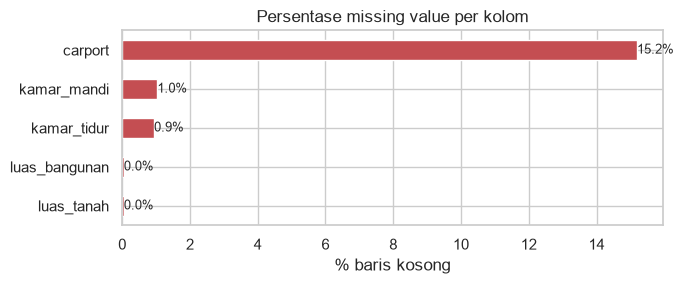

,listing,median_harga_juta,median_LB,median_LT
grup_carport,,,,
1,1156,775.00,80.00,107.00
2,419,"1,600.00",120.00,130.00
3+,138,"4,200.00",300.00,425.00
kosong,307,"1,750.00",160.00,160.00


Ada nilai carport = 0 di data mentah? False


In [4]:
missing = audit_missing(data)
display(missing)
fig = plot_missing_bars(missing)
plt.show()

cek_carport, ada_nol = audit_carport_mnar(data)
display(cek_carport)
print("Ada nilai carport = 0 di data mentah?", ada_nol)

,jumlah_kopian,persen_%
ID listing sama,0,0.00
Identik selain URL,63,3.12
Spesifikasi sama,438,21.68
Deskripsi sama,98,4.85


Grup deskripsi kembar dengan spesifikasi BERBEDA: 25 grup -> dipertahankan untuk grouped split


,batas_bawah,batas_atas,min,max,n_outlier,persen_%
kolom,,,,,,
harga,"-1,586,250,000.00","4,363,750,000.00","7,000,000.00","42,100,000,000.00",155.00,7.67
luas_tanah,-24.50,299.50,4.00,"4,222.00",240.00,11.89
luas_bangunan,-97.50,322.50,4.00,"2,408,150,000.00",167.00,8.27
kamar_tidur,-1.00,7.00,1.00,49.00,145.00,7.25
kamar_mandi,-2.00,6.00,1.00,49.00,115.00,5.75
carport,-0.50,3.50,1.00,15.00,88.00,5.14
log10(harga),8.03,10.11,6.85,10.62,21.00,1.04


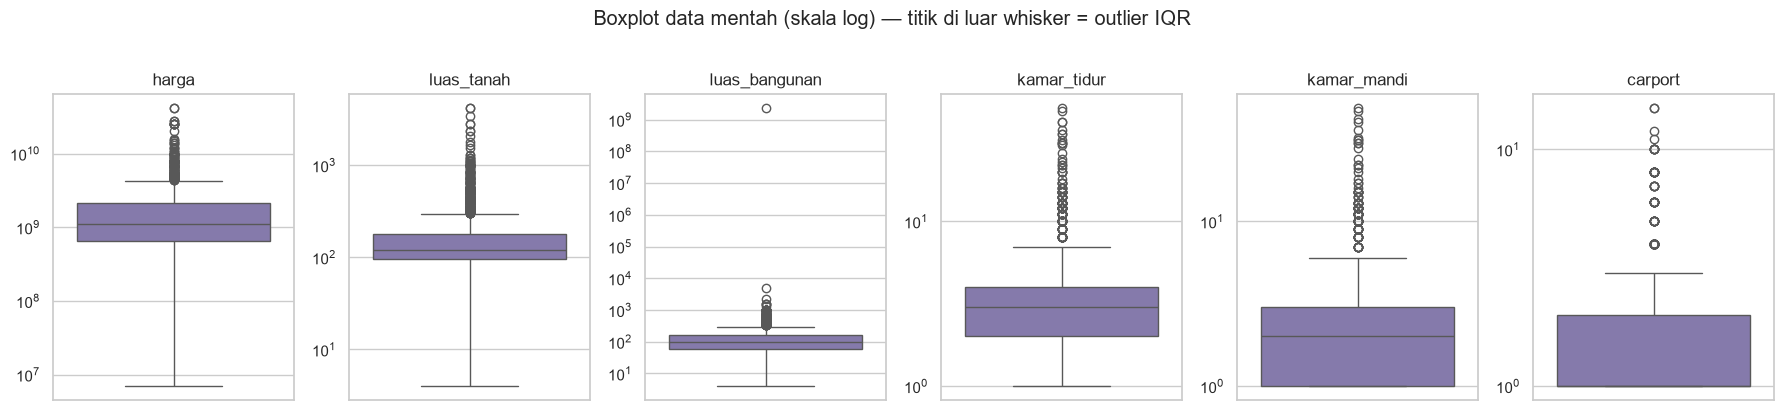

In [5]:
dup, n_beda = audit_duplicates(df_raw, data)
display(dup)
print(f"Grup deskripsi kembar dengan spesifikasi BERBEDA: {n_beda} grup -> dipertahankan untuk grouped split")

out_raw = tabel_outlier(data, NUM_COLUMNS)
out_raw.loc["log10(harga)"] = tabel_outlier(data.assign(lh=np.log10(data["harga"])), ["lh"]).iloc[0]
display(out_raw)
fig = plot_raw_boxplots(data, NUM_COLUMNS)
plt.show()

In [6]:
aturan = build_domain_rules(data)
ringkas_aturan = pd.DataFrame({"terdeteksi": aturan.sum(), "persen_%": aturan.mean() * 100})
display(ringkas_aturan)
print("LB > LT (dipertahankan):", (data["luas_bangunan"] > data["luas_tanah"]).sum(), "baris")

# Validasi judul yang diselamatkan frasa potensi ('cocok untuk homestay', dll.)
diselamatkan = flag_non_hunian(data["deskripsi"], strip_potensi=False) & ~aturan["non-hunian (judul)"]
print("Diselamatkan dari false positive:", int(diselamatkan.sum()))
display(data.loc[diselamatkan, ["deskripsi", "harga", "kamar_tidur"]])

,terdeteksi,persen_%
harga tidak wajar,11,0.54
kamar tidur > 10,91,4.50
kamar mandi > 10,71,3.51
luas <= 15 m2,3,0.15
luas bangunan > 5000 m2,2,0.10
LB > 3x LT,9,0.45
harga/m2 tanah < 1 jt,4,0.20
non-hunian (judul),187,9.26


LB > LT (dipertahankan): 495 baris
Diselamatkan dari false positive: 10


,deskripsi,harga,kamar_tidur
403,Rumah Tinggal Cocok Untuk Homestay Lokasi Deka...,"7,900,000,000.00",6.00
481,Rumah Cocok dibuat Kost dekat Hyatt Palagan,"875,000,000.00",8.00
492,Rumah Besar dkt jalan Taman Siswa Cocok Rmh Ti...,"2,000,000,000.00",5.00
601,Rumah Murah Nyaman Dlm Perum Cocok Homestay Ar...,"1,950,000,000.00",3.00
792,Rumah Modern Herritage di Prambanan Cocok Untu...,"1,300,000,000.00",2.00
793,Rumah Modern Herritage di Prambanan Cocok Untu...,"1,300,000,000.00",5.00
975,Rumah 2 Lantai siap huni legalitas SHM bisa un...,"1,370,000,000.00",4.00
1273,RUMAH BARU MEWAH 2 LANTAI ISTIMEWA DAN BERKUAL...,"1,970,000,000.00",5.00
1588,Rumah Murah Area Karangasem Bantul Cocok Homes...,"1,790,000,000.00",4.00
1591,Rumah Besar Murah Area Premium Cocok Rumah Kos...,"3,900,000,000.00",8.00


## 4. Cleaning Berurutan & Perbandingan Sebelum vs Sesudah
Setiap langkah dicatat dalam *cleaning log* dan hasil bersih disimpan ke `data/processed/listings_clean.csv` untuk dipakai notebook berikutnya.

,langkah,sisa_baris,dibuang,dibuang_kumulatif_%
0,Data mentah,2020,0,0.00
1,1. Luas tanah/bangunan kosong,2019,1,0.05
2,2. Duplikat spesifikasi,1581,438,21.73
3,3. Non-hunian (judul),1409,172,30.25
4,4. Nilai mustahil (aturan domain),1384,25,31.49


Data bersih: 1,384 baris (68.5% dari data mentah)


,harga,luas_tanah,luas_bangunan,kamar_tidur,kamar_mandi,carport
n_sebelum,2020,2019,2019,2001,1999,1713
n_sesudah,1384,1384,1384,1369,1368,1164
missing_sebelum,0,1,1,19,21,307
missing_sesudah,0,0,0,15,16,220
median_sebelum,"1,100,000,000.00",120.00,100.00,3.00,2.00,1.00
median_sesudah,"996,500,000.00",120.00,100.00,3.00,2.00,1.00
mean_sebelum,"1,840,271,287.13",185.71,"1,192,892.98",3.97,2.94,1.56
mean_sesudah,"1,584,281,069.36",169.17,128.86,3.24,2.31,1.45
max_sebelum,"42,100,000,000.00","4,222.00","2,408,150,000.00",49.00,49.00,15.00
max_sesudah,"16,000,000,000.00","4,222.00","1,000.00",10.00,10.00,15.00


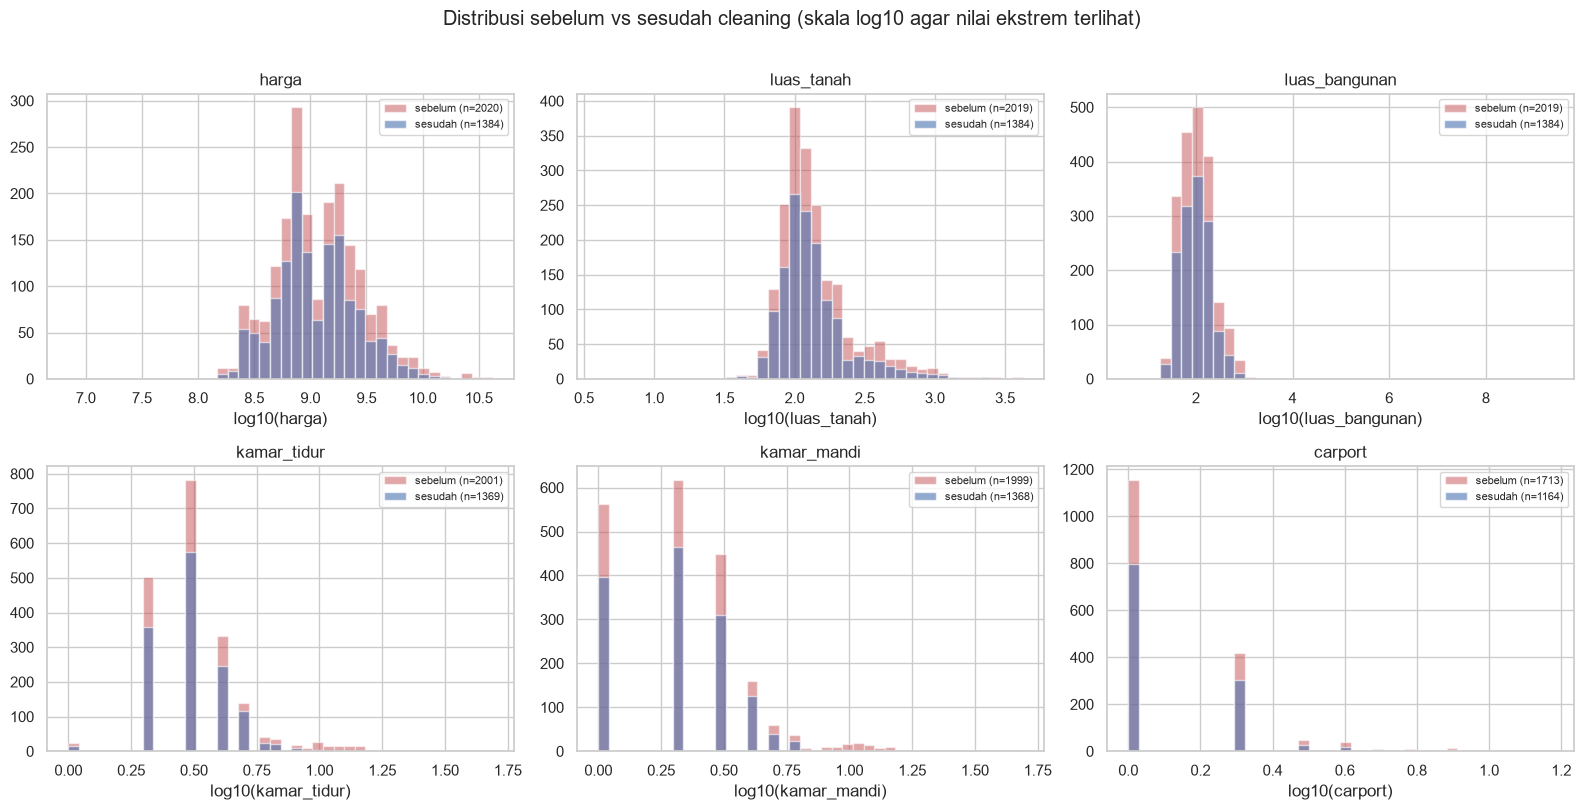

Checkpoint tersimpan: D:\Dev\Python\Semester-5\DataScience\pPrediksi_Harga_Rumah_DS\data\processed\listings_clean.csv


In [7]:
df_clean, log_df = clean_listings(data, aturan=aturan)
display(log_df)
print(f"Data bersih: {len(df_clean):,} baris ({len(df_clean)/len(data)*100:.1f}% dari data mentah)")

display(compare_before_after(data, df_clean).T)
fig = plot_before_after_histograms(data, df_clean, NUM_COLUMNS)
plt.show()

parsed_path, clean_path = save_clean_artifacts(data, df_clean)
print(f"Checkpoint tersimpan: {clean_path}")